# 05 — Karşılaştırma ve Hata Analizi

Bu notebook Faz 4 bulgularını (EVAL-03..07) tek yerde toplar: standart sonuç figürleri, model karşılaştırması, ufuk eğrisi, öznitelik ablasyonu, hava koşulu analizi, gün-bloklu bootstrap anlamlılığı ve dürüst yorum. **Eğitim veya yeniden hesaplama yapılmaz**; yalnızca kayıtlı CSV/PNG dosyaları okunur.

In [1]:
import sys, json, glob, subprocess
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from src import config, analysis
config.apply_plot_style()
print(config.summary())
M = config.METRICS_DIR
def fig(key):
    display(Image(filename=str(config.FIGURES_DIR / analysis.FIGURES[key])))

Yıllar: 2015-2016
Ham parquet: C:\Users\user\Desktop\merve\data\raw\pvdaq_sys4_2015_2016.parquet
Bölme: train 1 segment, val 6 segment, test 6 segment; veri sonu 2016-12-13 00:00
Hedef: ac_power [W]
Kapasite: 1.0 kW = 1000.0 W (nRMSE paydası: CAPACITY_W)


## 1. Standart figürler

### Kayıp eğrileri

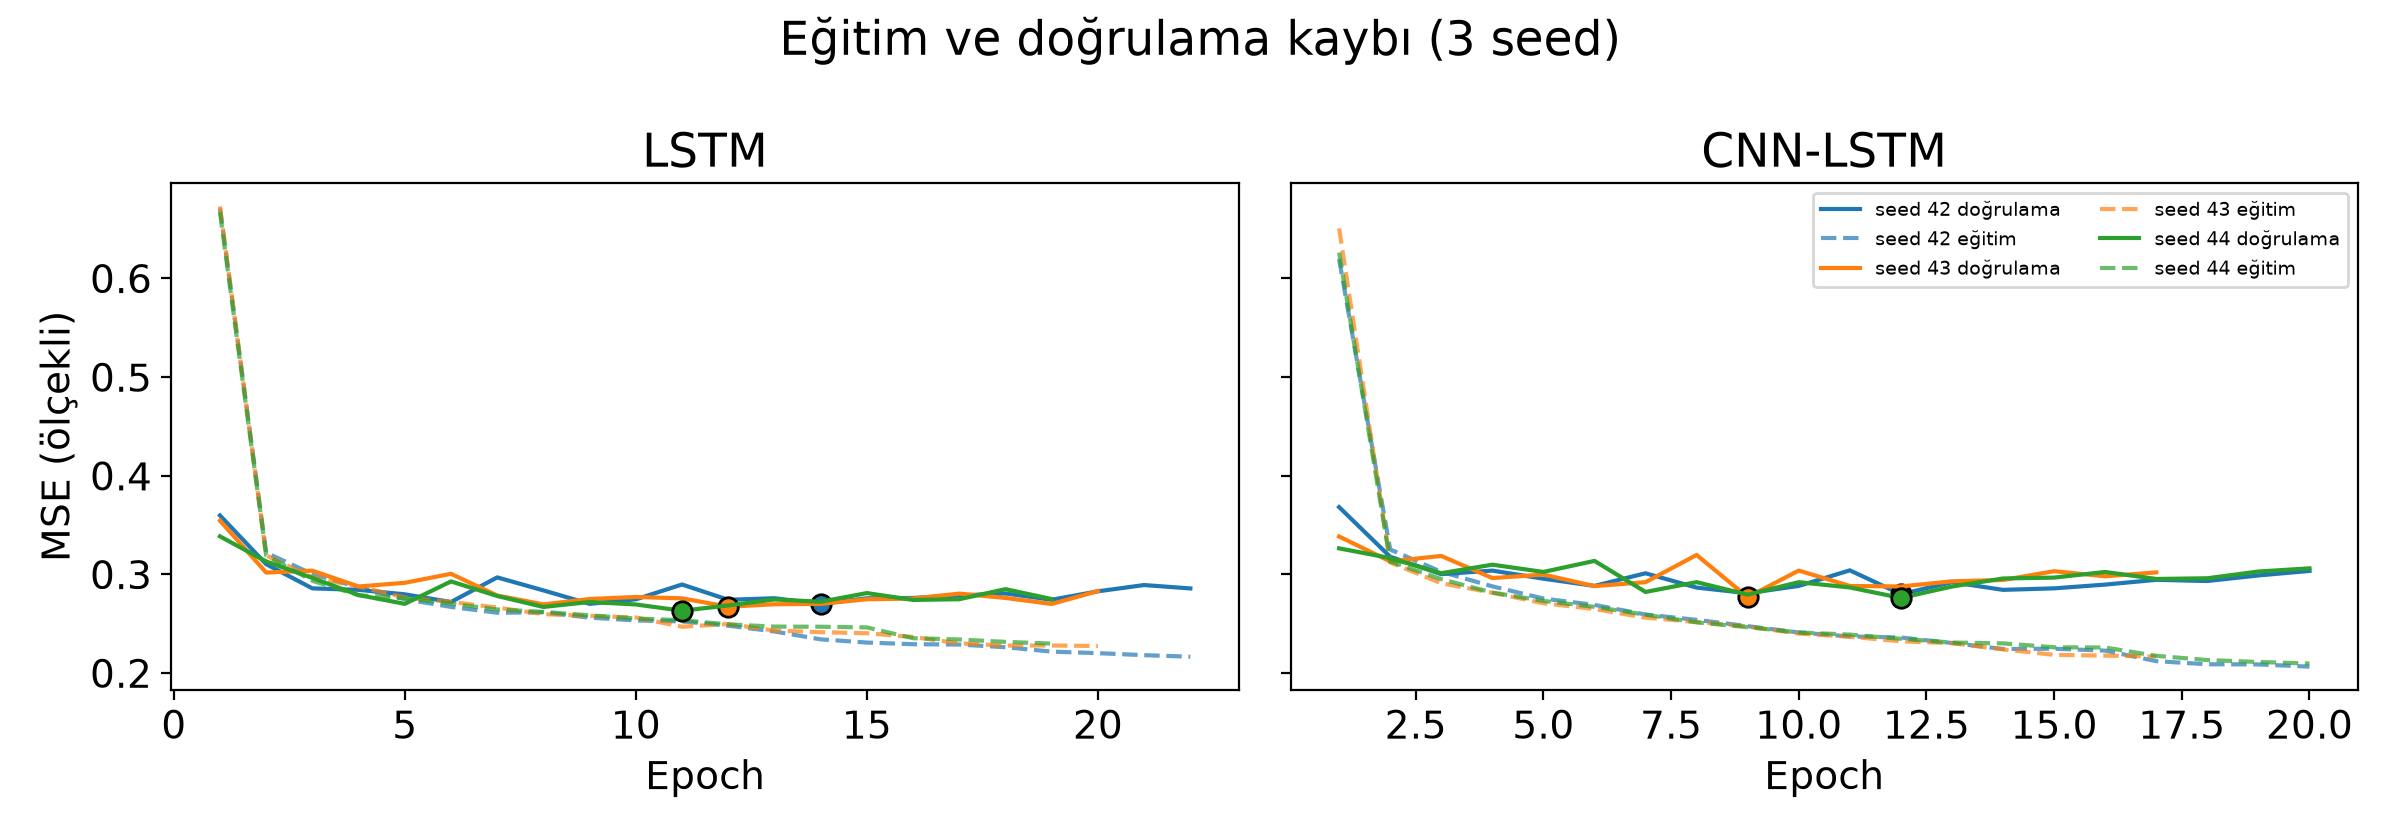

In [2]:
fig('kayip')

Eğitim kaybı düşmeye devam ederken doğrulama kaybı erken düzleşir; erken durdurma bu yüzden kullanılmıştır.

### Örnek günlerde tahmin ve gerçek

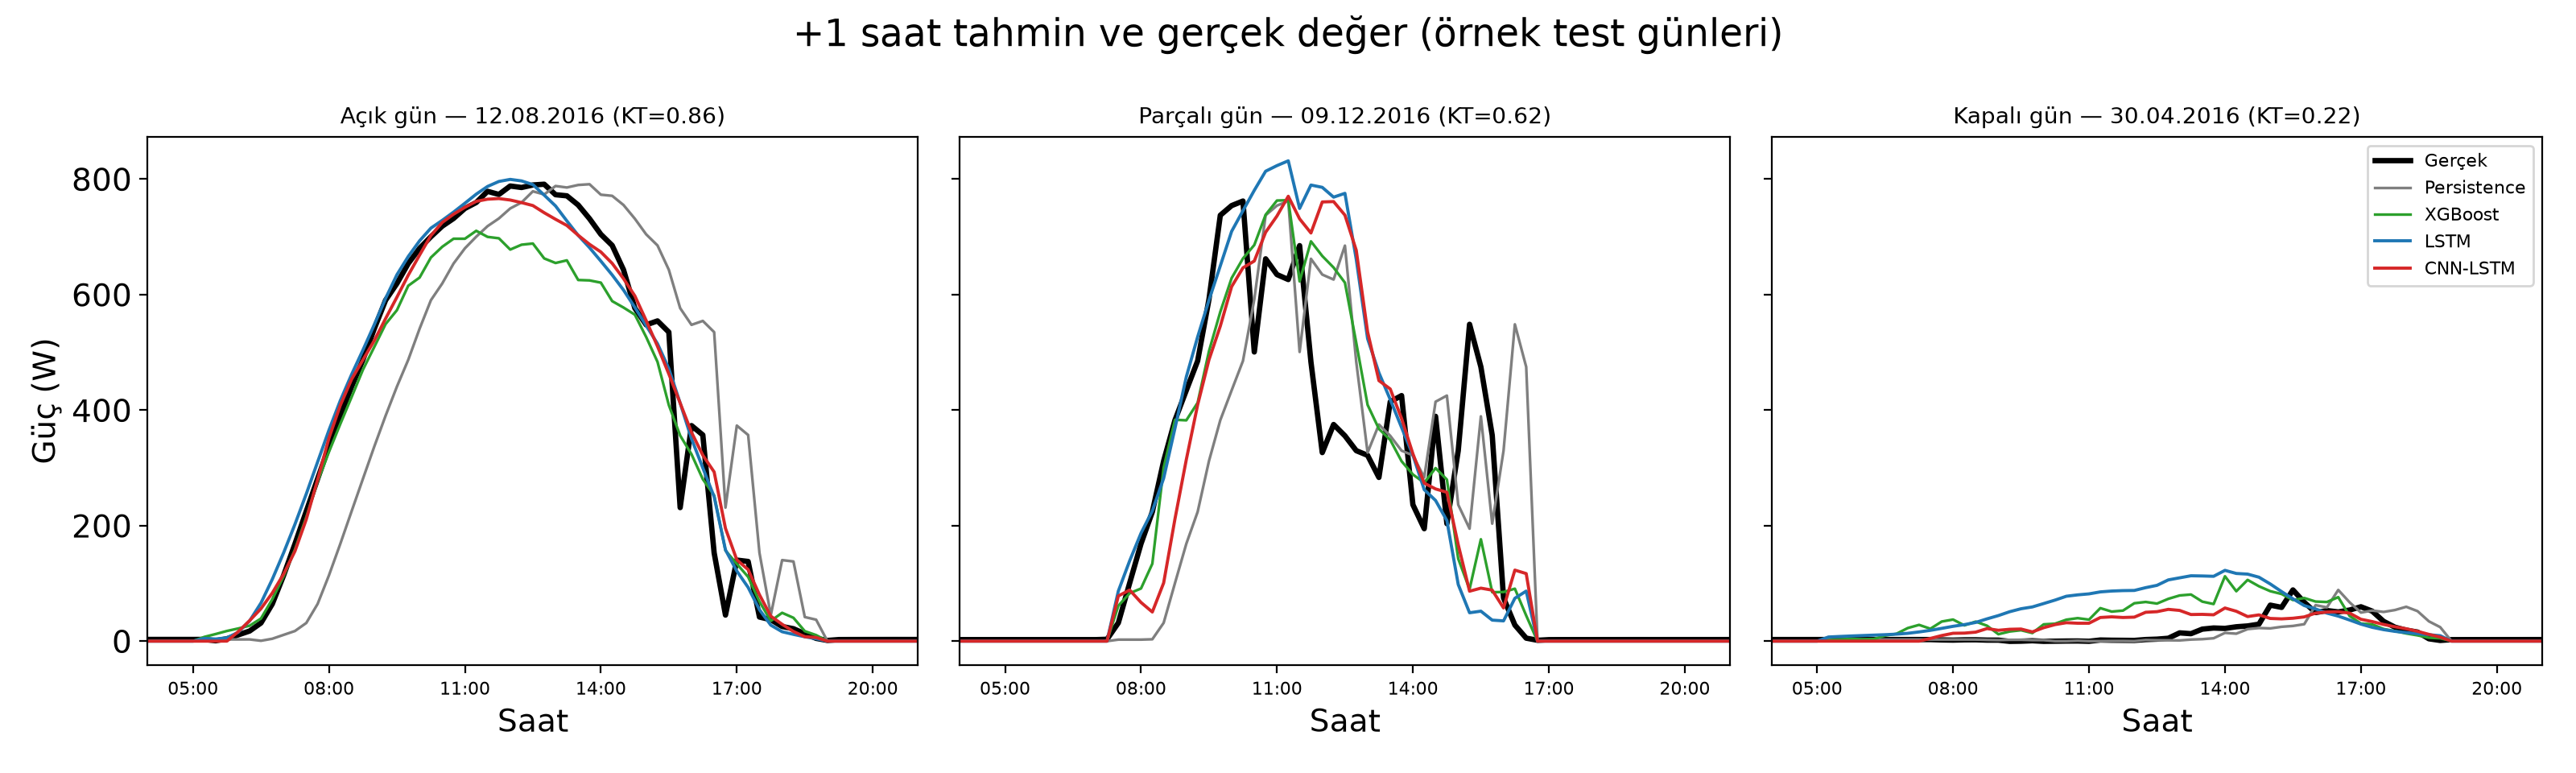

In [3]:
fig('tahmin')

Açık, parçalı ve kapalı birer örnek gün (KT medyanına en yakın test günleri; model hatasına bakılarak seçilmemiştir). Parçalı günde modeller ani düşüşleri geriden izler.

### Saate göre hata

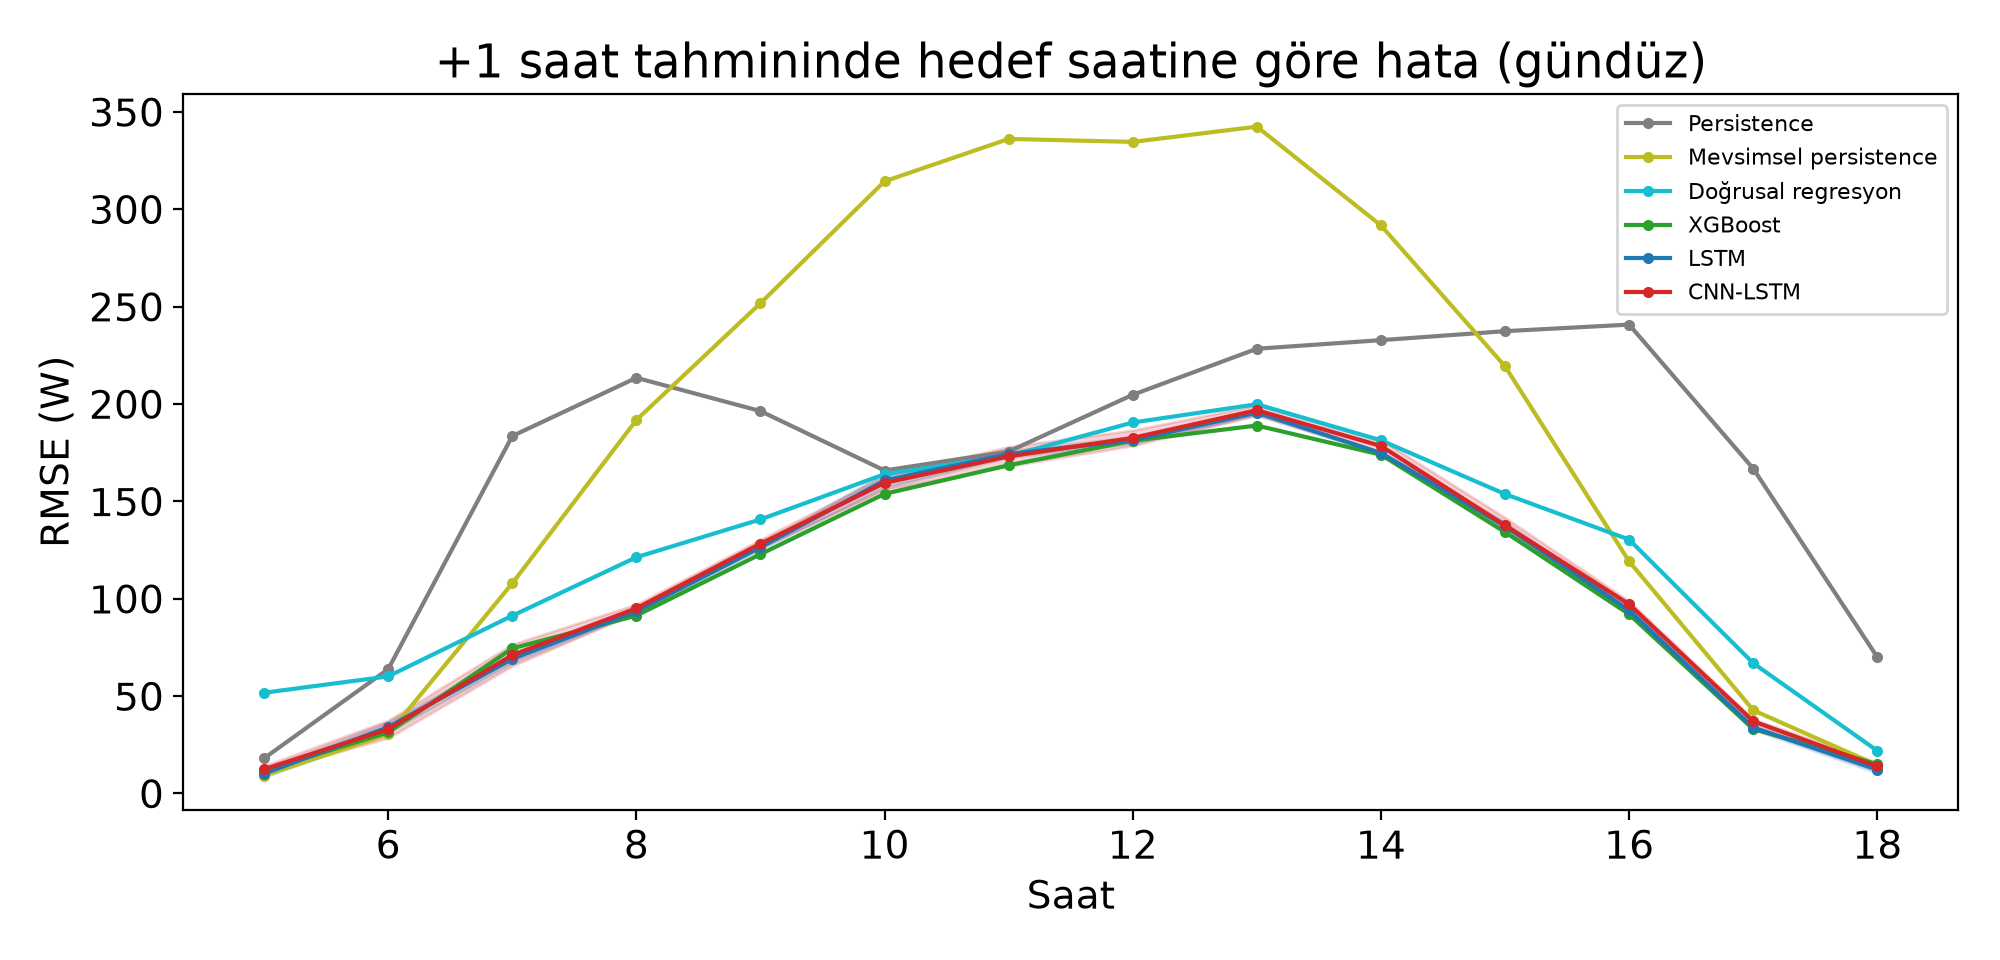

In [4]:
fig('saat')

In [5]:
h = pd.read_csv(M / 'hour_metrics.csv'); h = h[h['n'] >= 30]
hm = h.groupby(['saat', 'model'])['RMSE_W'].mean().unstack()
zs = hm.mean(axis=1).idxmax()
dl = hm.loc[zs, ['lstm', 'cnn_lstm']].idxmin()
display(Markdown(f"Model ortalaması hatası en yüksek saat {int(zs):02d}:00'dır. Bu saatte XGBoost RMSE {hm.loc[zs, 'xgboost']:.1f} W, en iyi DL ({analysis.label(dl)}) {hm.loc[zs, dl]:.1f} W; fark {hm.loc[zs, dl] - hm.loc[zs, 'xgboost']:+.1f} W (DL - XGBoost)."))

Model ortalaması hatası en yüksek saat 13:00'dır. Bu saatte XGBoost RMSE 188.9 W, en iyi DL (LSTM) 195.5 W; fark +6.6 W (DL - XGBoost).

### Model karşılaştırması

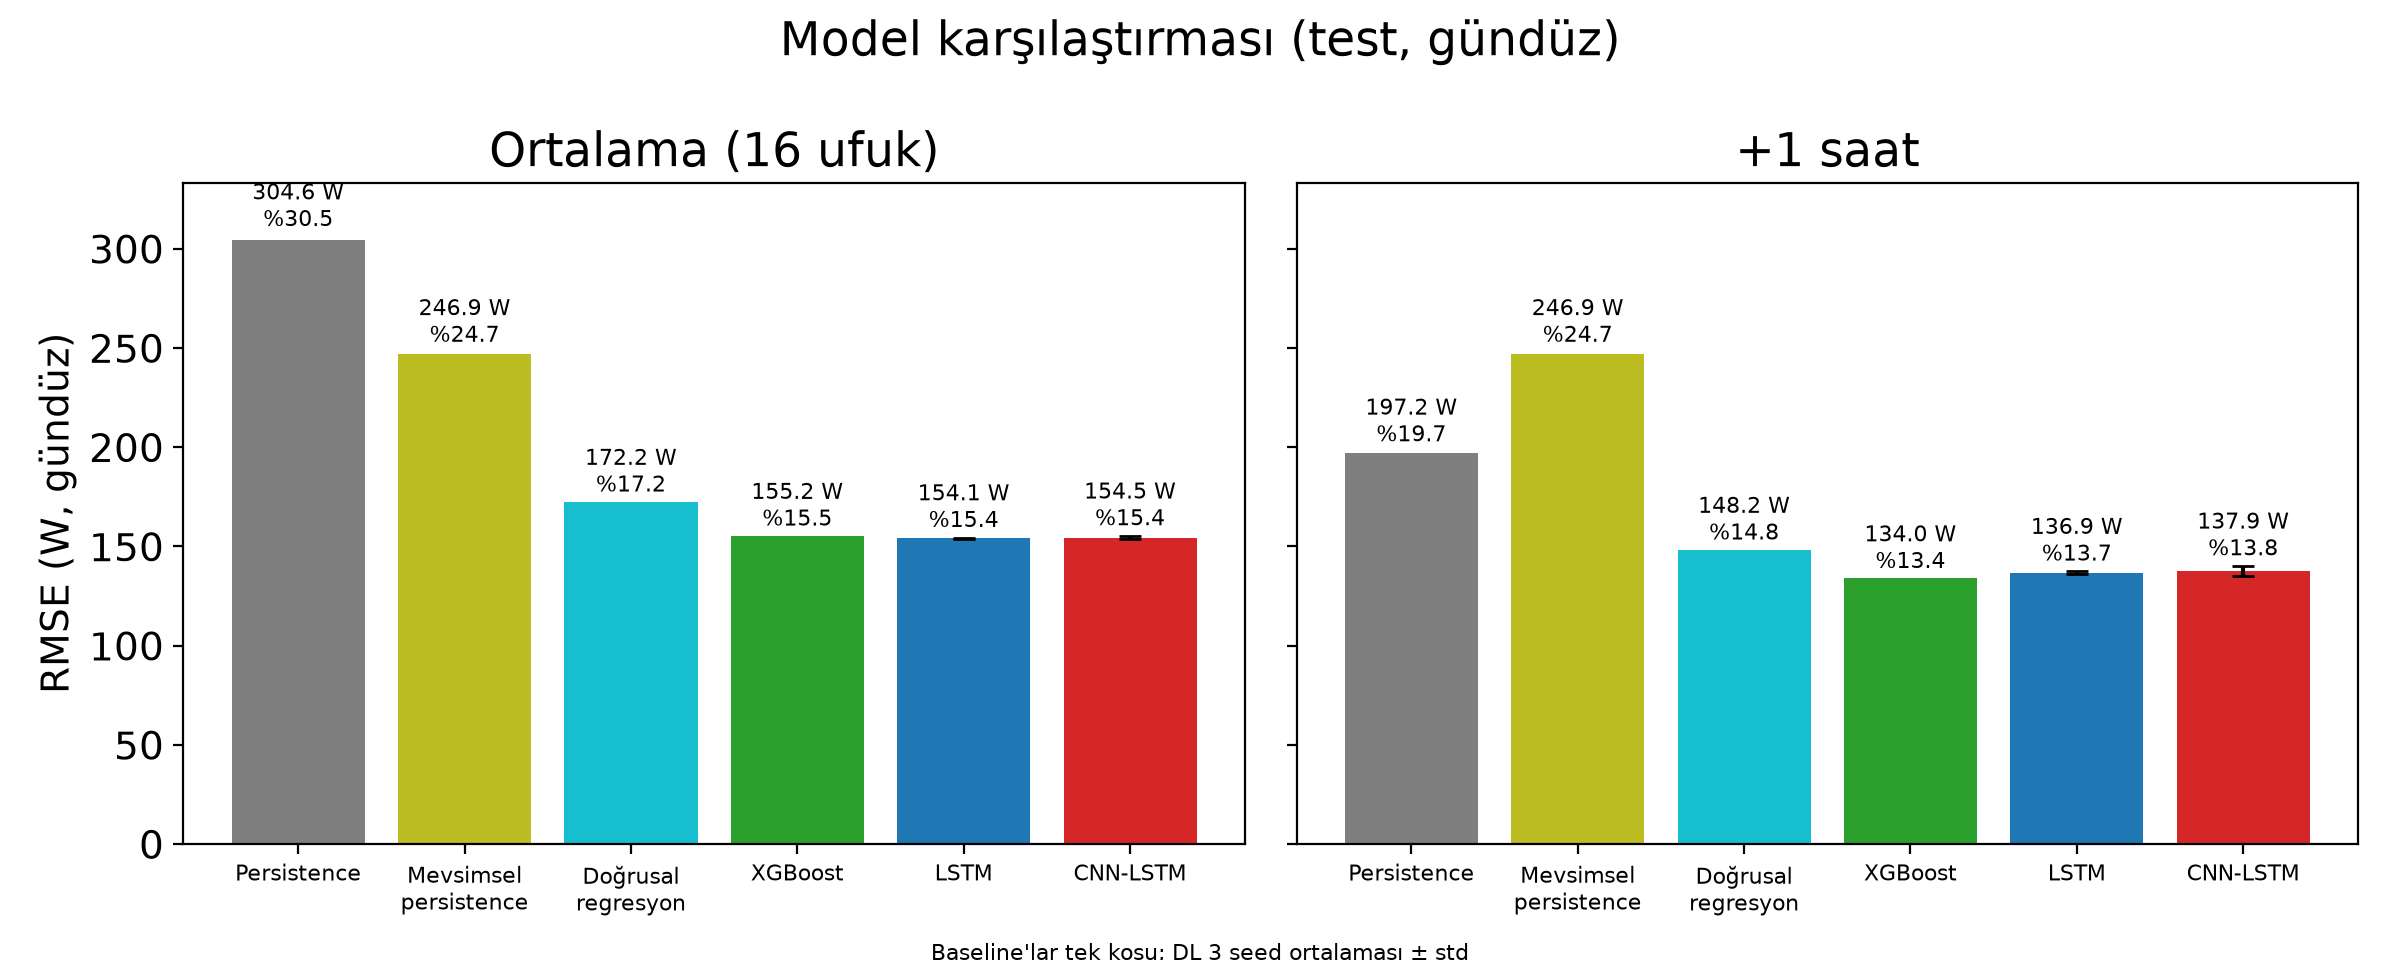

In [6]:
fig('karsilastirma')

In [7]:
_s = pd.read_csv(M / 'summary.csv'); _s = _s[(_s['mask'] == 'day') & (_s['scope'] == 'mean16')].set_index('model')['RMSE_W_mean']
k = pd.read_csv(M / 'kazanan_ozet.csv'); _r = k[k['kesit_turu'] == 'ufuk_ort'].iloc[0]
display(Markdown(f"16-ufuk ortalamasında RMSE: LSTM {_s['lstm']:.1f} W, CNN-LSTM {_s['cnn_lstm']:.1f} W, XGBoost {_s['xgboost']:.1f} W, Doğrusal regresyon {_s['linreg']:.1f} W, persistence {_s['persistence']:.1f} W. "
                 f"En iyi DL ile en iyi baseline farkı {_r['fark_W']:+.1f} W; %95 GA [{_r['ci_low']:.1f}, {_r['ci_high']:.1f}]; karar: {_r['dl_baseline_gecti']} ({_r['karar_olcutu']})."))

16-ufuk ortalamasında RMSE: LSTM 154.1 W, CNN-LSTM 154.5 W, XGBoost 155.2 W, Doğrusal regresyon 172.2 W, persistence 304.6 W. En iyi DL ile en iyi baseline farkı -1.0 W; %95 GA [-5.4, 3.7]; karar: belirsiz (bootstrap).

## 2. Model karşılaştırma tablosu (gündüz, RMSE W / nRMSE)

In [8]:
s = pd.read_csv(M / 'summary.csv')
d = s[s['mask'] == 'day'].copy()
order = [m for m in analysis.MODEL_ORDER if m in set(d['model'])]
rm = d.pivot(index='model', columns='scope', values='RMSE_W_mean').loc[order].round(1)
sd = d.pivot(index='model', columns='scope', values='RMSE_W_std').loc[order].round(1)
nr = d.pivot(index='model', columns='scope', values='nRMSE_mean').loc[order].round(4)
print('RMSE_W (ortalama)'); print(rm.to_string()); print('\nRMSE_W (seed std; baseline tek koşu = 0)'); print(sd.to_string())
print('\nnRMSE (ortalama)'); print(nr.to_string())

RMSE_W (ortalama)
scope                    h4  mean16
model                              
persistence           197.2   304.6
seasonal_persistence  246.9   246.9
linreg                148.2   172.2
xgboost               134.0   155.2
lstm                  136.9   154.1
cnn_lstm              137.9   154.5

RMSE_W (seed std; baseline tek koşu = 0)
scope                  h4  mean16
model                            
persistence           0.0     0.0
seasonal_persistence  0.0     0.0
linreg                0.0     0.0
xgboost               0.0     0.0
lstm                  0.8     0.3
cnn_lstm              2.5     0.8

nRMSE (ortalama)
scope                     h4  mean16
model                               
persistence           0.1972  0.3046
seasonal_persistence  0.2469  0.2469
linreg                0.1482  0.1722
xgboost               0.1340  0.1552
lstm                  0.1369  0.1541
cnn_lstm              0.1379  0.1545


## 3. Ufuk eğrisi

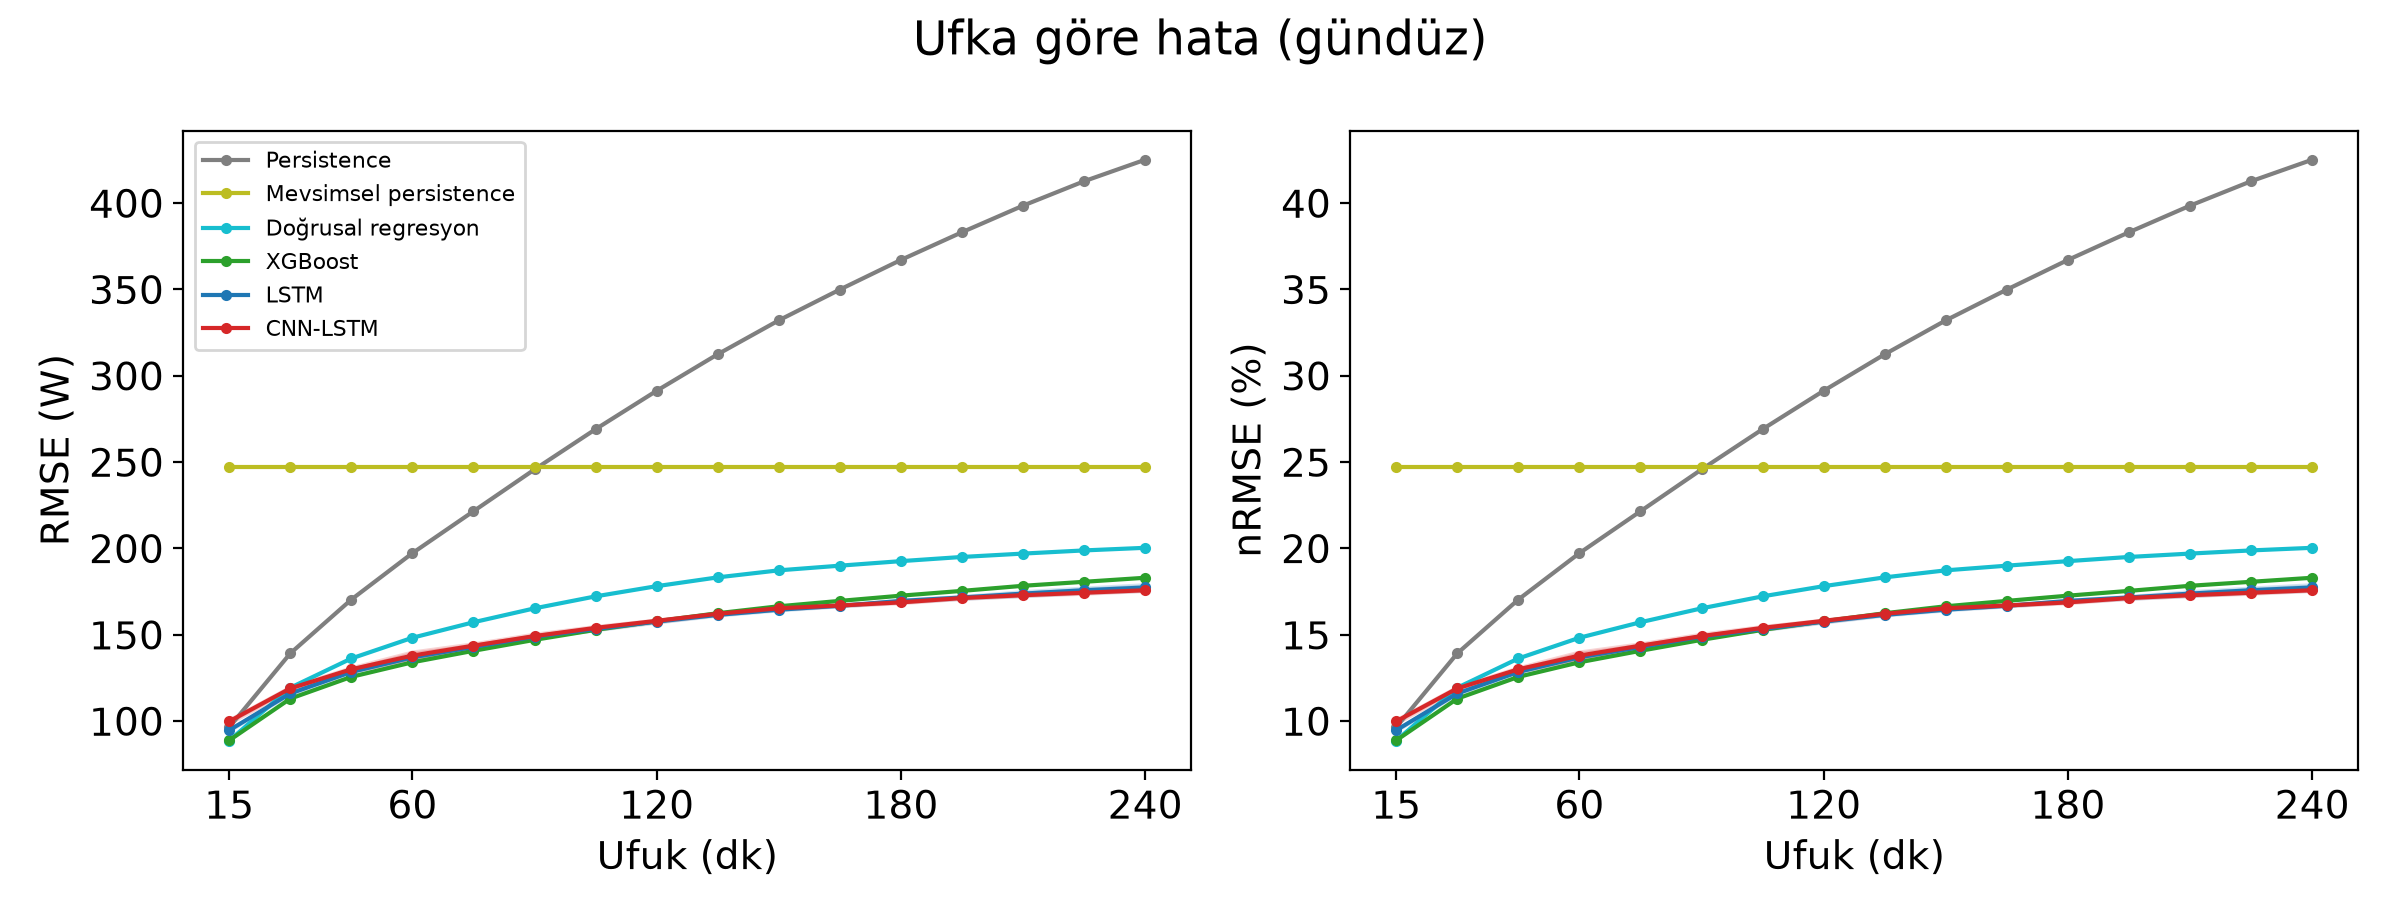

In [9]:
fig('ufuk')

In [10]:
print(pd.read_csv(M / 'ufuk_tablosu.csv').round(1).to_string(index=False))

 horizon_min  persistence_RMSE_W  persistence_nRMSE  seasonal_persistence_RMSE_W  seasonal_persistence_nRMSE  linreg_RMSE_W  linreg_nRMSE  xgboost_RMSE_W  xgboost_nRMSE  lstm_RMSE_W  lstm_nRMSE  cnn_lstm_RMSE_W  cnn_lstm_nRMSE
          15                96.4                0.1                        246.9                         0.2           88.6           0.1            88.8            0.1         94.6         0.1             99.8             0.1
          30               139.2                0.1                        246.9                         0.2          119.3           0.1           113.0            0.1        115.9         0.1            118.9             0.1
          45               170.4                0.2                        246.9                         0.2          136.2           0.1           125.6            0.1        128.4         0.1            129.9             0.1
          60               197.2                0.2                        246.9            

In [11]:
_u = k[k['kesit_turu'] == 'ufuk']
_satir = [f"- {r.kesit}: kazanan {analysis.label(r.en_iyi_model)}, DL baseline'ı geçti mi: {r.dl_baseline_gecti} (fark {r.fark_W:+.1f} W, GA [{r.ci_low:.1f}, {r.ci_high:.1f}])" for r in _u.itertuples()]
_nl = chr(10)
display(Markdown(f"Ufuk bazında kazananlar:{_nl}{_nl}{_nl.join(_satir)}"))

Ufuk bazında kazananlar:

- +15 dk: kazanan Doğrusal regresyon, DL baseline'ı geçti mi: hayır (fark +6.0 W, GA [4.0, 8.1])
- +1 saat: kazanan XGBoost, DL baseline'ı geçti mi: hayır (fark +2.9 W, GA [0.4, 5.4])
- +2 saat: kazanan LSTM, DL baseline'ı geçti mi: belirsiz (fark -0.2 W, GA [-5.0, 4.1])
- +4 saat: kazanan CNN-LSTM, DL baseline'ı geçti mi: evet (fark -7.2 W, GA [-14.2, -0.3])

## 4. Öznitelik ablasyonu

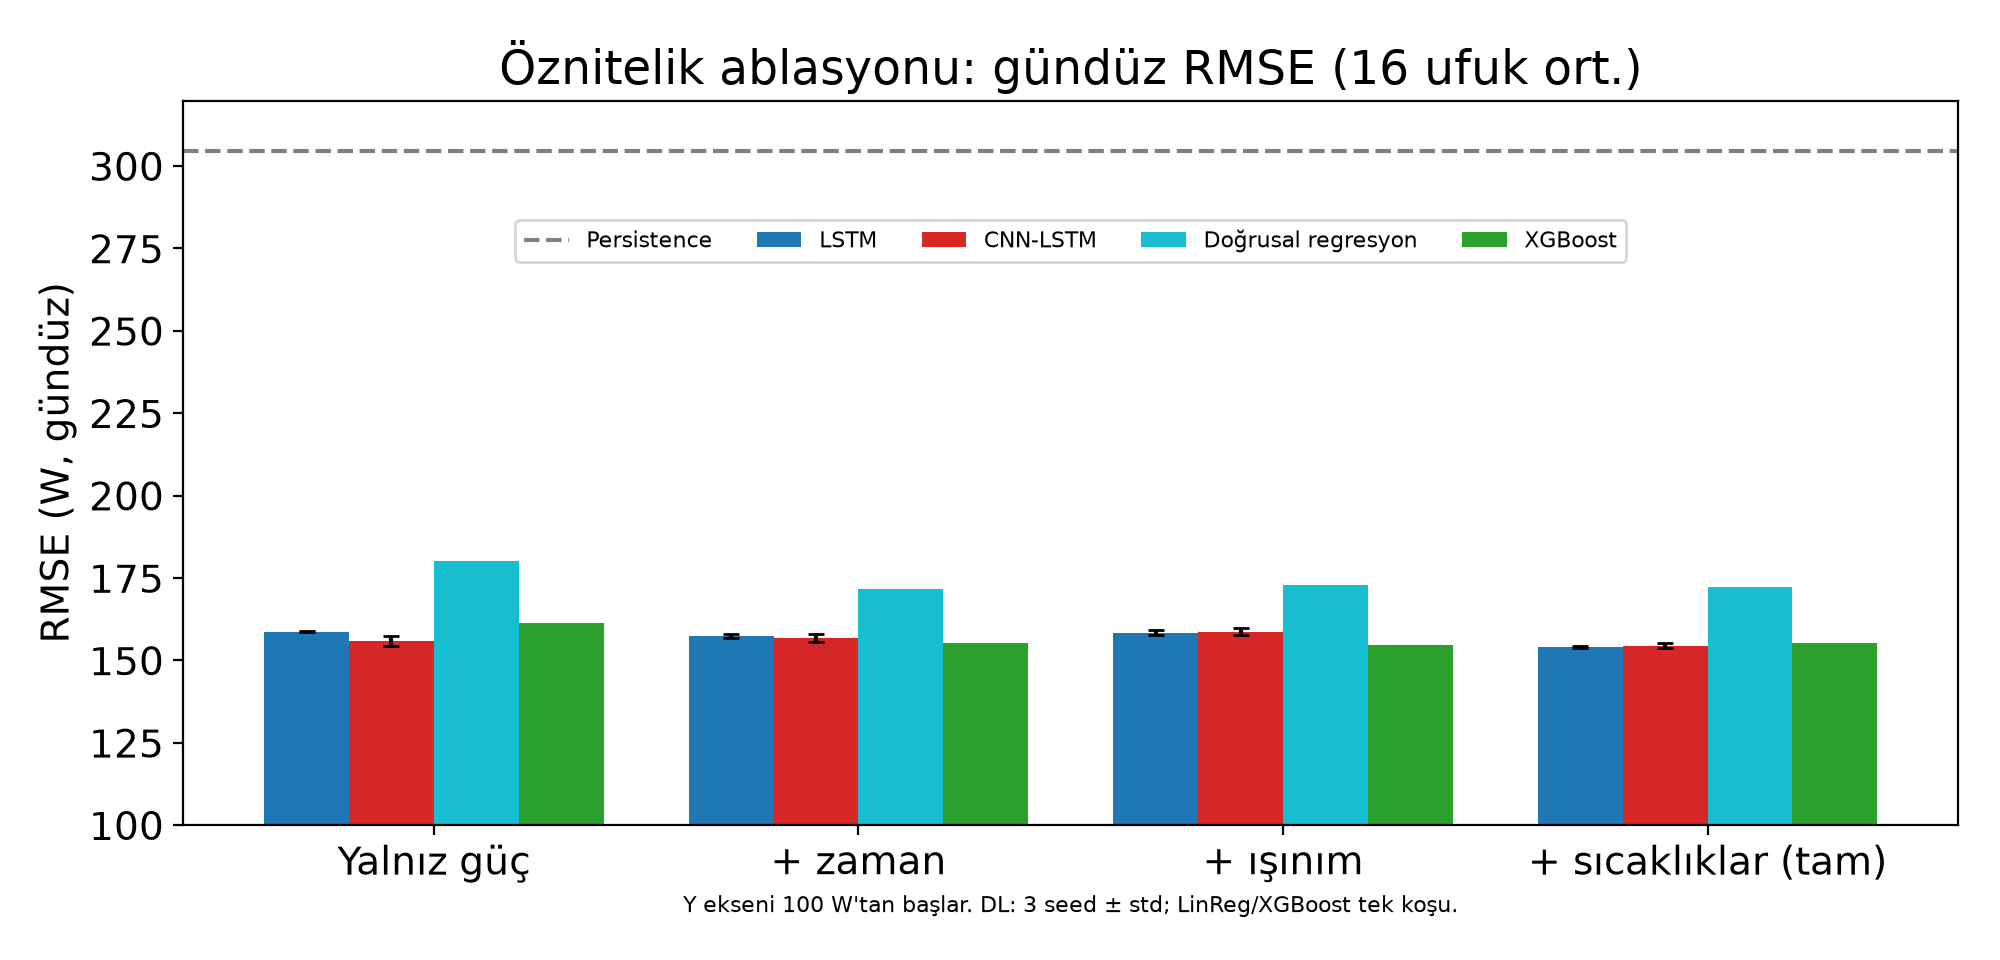

In [12]:
fig('ablasyon')

In [13]:
a = pd.read_csv(M / 'ablation_summary.csv')
a = a[(a['mask'] == 'day') & (a['scope'] == 'mean16')]
print(a.pivot(index='grup', columns='model', values='RMSE_W_mean').round(1).to_string())
print('\nkatki_W (bir önceki gruba göre; negatif = iyileşme)')
print(a.pivot(index='grup', columns='model', values='katki_W').round(2).to_string())

model     cnn_lstm  linreg   lstm  xgboost
grup                                      
A_guc        155.9   180.1  158.8    161.4
B_zaman      156.8   171.8  157.4    155.3
C_isinim     158.7   172.7  158.4    154.6
D_tam        154.5   172.2  154.1    155.2

katki_W (bir önceki gruba göre; negatif = iyileşme)
model     cnn_lstm  linreg  lstm  xgboost
grup                                     
A_guc          NaN     NaN   NaN      NaN
B_zaman       0.84   -8.31 -1.40    -6.10
C_isinim      1.98    0.99  1.07    -0.64
D_tam        -4.25   -0.58 -4.28     0.54


In [14]:
_c = a[a['grup'] == 'C_isinim'].set_index('model')['katki_W']
_ab = k[k['kesit_turu'] == 'ablasyon'].set_index('kesit')['dl_baseline_gecti']
_kat = ', '.join(f"{analysis.label(m)} {_c[m]:+.1f} W" for m in ('lstm', 'cnn_lstm') if m in _c.index)
display(Markdown(f"Işınım grubu (C) katkısı (bir önceki gruba göre): {_kat}. Ablasyon kesit kararları: " + '; '.join(f'{g} = {v}' for g, v in _ab.items()) + ". XGBoost ve Doğrusal regresyon tek koşudur; bu modeller için seed std yoktur."))

Işınım grubu (C) katkısı (bir önceki gruba göre): LSTM +1.1 W, CNN-LSTM +2.0 W. Ablasyon kesit kararları: A_guc = evet; B_zaman = belirsiz; C_isinim = belirsiz; D_tam = belirsiz. XGBoost ve Doğrusal regresyon tek koşudur; bu modeller için seed std yoktur.

## 5. Hava koşuluna göre hata

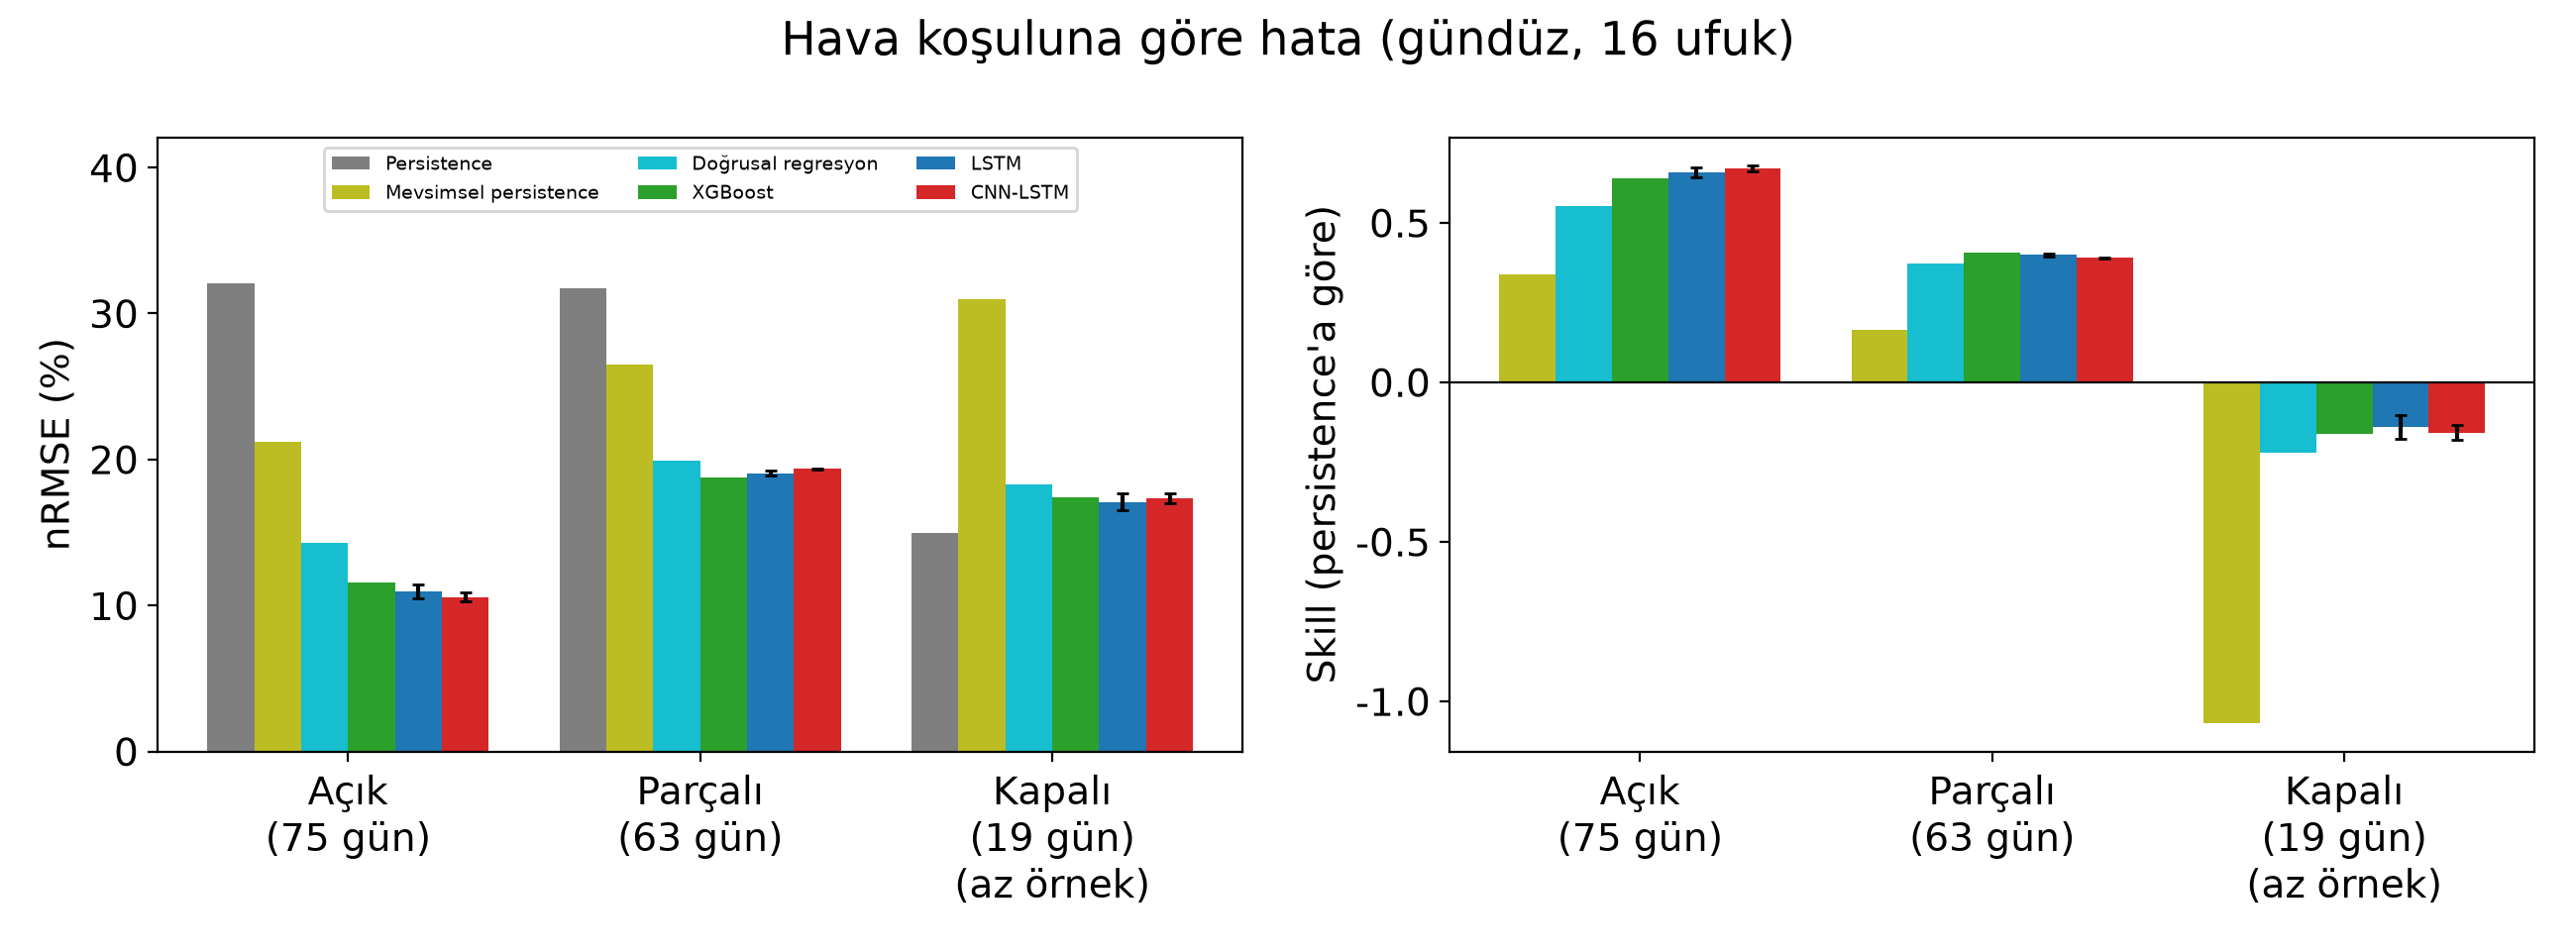

In [15]:
fig('hava')

In [16]:
wd = pd.read_csv(M / 'weather_days.csv')
print('Tüm günler:'); print(wd['sinif_ad'].value_counts().to_string())
print('\nTest günleri:'); print(wd[wd['test_gunu']]['sinif_ad'].value_counts().to_string())
w = pd.read_csv(M / 'weather_metrics.csv')
w = w[w['scope'] == 'mean16']
pv = w.groupby(['sinif_ad', 'model'])['RMSE_W'].mean().unstack().reindex(columns=analysis.MODEL_ORDER).round(1)
print('\nRMSE_W (16-ufuk ortalaması)'); print(pv.to_string())

Tüm günler:
sinif_ad
Açık       297
Parçalı    295
Kapalı     120

Test günleri:
sinif_ad
Açık       75
Parçalı    63
Kapalı     19

RMSE_W (16-ufuk ortalaması)
model     persistence  seasonal_persistence  linreg  xgboost   lstm  cnn_lstm
sinif_ad                                                                     
Açık            320.3                 212.4   142.9    115.6  109.8     105.7
Kapalı          149.8                 310.0   183.0    173.9  170.8     173.4
Parçalı         317.1                 265.1   199.2    187.8  190.6     193.5


In [17]:
_tc = wd[wd['test_gunu']]['sinif_ad'].value_counts()
_hv = k[k['kesit_turu'] == 'hava']
_sat = '; '.join(f"{r.kesit}: kazanan {analysis.label(r.en_iyi_model)}, karar {r.dl_baseline_gecti}" for r in _hv.itertuples())
display(Markdown(f"Test günü sayıları: " + ', '.join(f'{i} {n}' for i, n in _tc.items()) + '. ' + _sat + '.'))

Test günü sayıları: Açık 75, Parçalı 63, Kapalı 19. Kapalı (19 gün): kazanan Persistence, karar belirsiz; Parçalı (63 gün): kazanan XGBoost, karar belirsiz; Açık (75 gün): kazanan CNN-LSTM, karar evet.

## 6. Anlamlılık: gün-bloklu bootstrap (B = 1000)
Fark = model_a - model_b (negatif: model_a daha iyi).

In [18]:
b = pd.read_csv(M / 'bootstrap_fark.csv')
print(b.round(2).to_string(index=False))

 model_a     model_b kapsam  rmse_a  rmse_b  fark_W  ci_low  ci_high  anlamli  n_gun
    lstm     xgboost     h1   94.65   88.79    5.86    4.30     7.46     True    157
    lstm     xgboost     h4  136.87  134.00    2.88    0.49     5.42     True    157
    lstm     xgboost     h8  157.58  157.76   -0.18   -5.15     4.96    False    157
    lstm     xgboost    h16  177.34  182.96   -5.62  -12.51     1.69    False    157
    lstm     xgboost mean16  154.14  155.17   -1.03   -5.26     3.67    False    157
cnn_lstm     xgboost     h1   99.80   88.79   11.02    9.46    12.53     True    157
cnn_lstm     xgboost     h4  137.89  134.00    3.89    1.23     6.19     True    157
cnn_lstm     xgboost     h8  158.01  157.76    0.25   -3.90     4.65    False    157
cnn_lstm     xgboost    h16  175.73  182.96   -7.23  -14.06    -0.56     True    157
cnn_lstm     xgboost mean16  154.50  155.17   -0.67   -5.01     3.76    False    157
    lstm      linreg     h1   94.65   88.63    6.02    4.00     8

## 7. Dürüstlük: kesit bazında kazanan

Kazanan seçimi test kümesinde yapılmıştır, çoklu karşılaştırma düzeltmesi yoktur (bkz. yorum.md Yöntem Notu). Karar tüm kesitlerde gün-bloklu bootstrap ile verilir (karar_olcutu sütunu).

In [19]:
k = pd.read_csv(M / 'kazanan_ozet.csv')
print(k['karar_olcutu'].value_counts().to_string())
print(k['dl_baseline_gecti'].value_counts().to_string())
print()
print(k.round(2).to_string(index=False))

karar_olcutu
bootstrap    30
dl_baseline_gecti
belirsiz    23
evet         4
hayır        3

kesit_turu              kesit         en_iyi_model  en_iyi_RMSE_W      en_iyi_baseline  baseline_RMSE_W en_iyi_dl  dl_RMSE_W  dl_std_W  fark_W dl_baseline_gecti karar_olcutu  ci_low  ci_high  boot_fark_W  n_gun_boot
      ufuk             +15 dk               linreg          88.63               linreg            88.63      lstm      94.65      0.49    6.01             hayır    bootstrap    4.02     8.06         6.02         157
      ufuk            +1 saat              xgboost         134.00              xgboost           134.00      lstm     136.87      0.84    2.87             hayır    bootstrap    0.40     5.41         2.88         157
      ufuk            +2 saat                 lstm         157.58              xgboost           157.76      lstm     157.58      0.69   -0.18          belirsiz    bootstrap   -4.96     4.13        -0.18         157
      ufuk            +4 saat             c

In [20]:
print('DL baseline\'ı geçemedi (hayır):')
print(k[k['dl_baseline_gecti'] == 'hayır'][['kesit_turu', 'kesit', 'en_iyi_baseline', 'baseline_RMSE_W', 'en_iyi_dl', 'dl_RMSE_W', 'fark_W']].round(1).to_string(index=False))

DL baseline'ı geçemedi (hayır):
kesit_turu   kesit en_iyi_baseline  baseline_RMSE_W en_iyi_dl  dl_RMSE_W  fark_W
      ufuk  +15 dk          linreg             88.6      lstm       94.6     6.0
      ufuk +1 saat         xgboost            134.0      lstm      136.9     2.9
      saat   13:00         xgboost            188.9      lstm      195.5     6.6


## 8. Yorum

In [21]:
display(Markdown((PROJECT_ROOT / 'results' / 'yorum.md').read_text(encoding='utf-8')))

# Sonuçların Yorumu

Bu belgedeki her sayı `results/metrics/` altındaki CSV dosyalarından alınmıştır (kaynak dosya adı parantez içinde belirtilmiştir). Hatalar, aksi belirtilmedikçe test döneminde yalnızca gündüz saatleri (güneş yüksekliği > 0) için W cinsinden RMSE'dir. Derin öğrenme (DL) sayıları 3 seed'in (42, 43, 44) ortalamasıdır; XGBoost, Doğrusal regresyon ve persistence modelleri tek koşuludur, bu yüzden bu modeller için seed standart sapması yoktur ve kesitler arası küçük farklar için yalnızca DL tarafının belirsizliği ölçülebilmiştir.

## Özet

- 16 ufkun ortalamasında (summary.csv) LSTM 154,1 W (seed std 0,3), CNN-LSTM 154,5 W (std 0,8), XGBoost 155,2 W, Doğrusal regresyon 172,2 W, mevsimsel persistence 246,9 W ve persistence 304,6 W RMSE verir. DL ile XGBoost arasındaki fark gün-bloklu bootstrap ile anlamlı değildir (LSTM - XGBoost: -1,0 W, %95 GA [-5,3; +3,7], bootstrap_fark.csv).
- DL, kısa ufukta (+15 dk ve +1 saat) en güçlü baseline'ı geçemedi; uzun ufukta (+4 saat) CNN-LSTM XGBoost'a göre daha iyidir ve fark anlamlıdır (bootstrap_fark.csv). Geçiş noktası yaklaşık +2 saattir (ufuk_tablosu.csv).
- Açık günlerde DL en iyi sonucu verir; kapalı günlerde persistence, parçalı günlerde XGBoost nokta tahminde en iyidir ancak bu iki sınıftaki DL-baseline farkı belirsizdir (weather_metrics.csv, kazanan_ozet.csv).
- Öznitelik ablasyonunda ışınım grubu ölçülebilir bir kazanç sağlamamıştır (aşağıda).
- kazanan_ozet.csv'de 30 kesitten 3'ünde DL baseline'ı geçemedi, 23'ünde fark belirsiz, 4'ünde DL daha iyidir (tüm kesitler aynı kuralla, gün-bloklu bootstrap %95 GA ile karara bağlanmıştır; ayrıntı "Yöntem Notu: Karar Ölçütü" bölümünde). Dolayısıyla genel tablo "DL klasik baseline'lara göre belirgin üstün" değil, "kısa ufukta (+15 dk, +1 saat) ve 13:00'te baseline geride değil önde; uzun ufuk (+4 saat), açık hava, ablasyon grubu A ve 18:00'te DL anlamlı biçimde önde; kalan 23 kesitte fark ölçülebilir değil" şeklindedir.

## Ufka Göre (sonuc_06)

Kaynak: ufuk_tablosu.csv.

| Ufuk | Persistence | Doğrusal regresyon | XGBoost | LSTM | CNN-LSTM |
|------|-------------|--------------------|---------|------|----------|
| +15 dk | 96,4 | 88,6 | 88,8 | 94,6 | 99,8 |
| +1 saat | 197,2 | 148,2 | 134,0 | 136,9 | 137,9 |
| +2 saat | 291,3 | 178,1 | 157,8 | 157,6 | 158,0 |
| +4 saat | 425,1 | 200,3 | 183,0 | 177,3 | 175,7 |

Persistence ufukla hızla bozulur (96,4 W'tan 425,1 W'a). Mevsimsel persistence her ufukta 246,9 W'tır: tahmin, pencerenin ilk 16 adımından alınan "dünün aynı saatleri"dir ve bu değer hedef ufkuna bağlı olarak değişmeyen bir hata dağılımı verir, bu yüzden düz bir çizgi görünür (ufuk_tablosu.csv). +15 dk'da DL, Doğrusal regresyon ve XGBoost'tan daha kötüdür (LSTM 94,6 W, CNN-LSTM 99,8 W; en iyisi Doğrusal regresyon 88,6 W); hatta CNN-LSTM persistence'tan (96,4 W) da geridedir. +4 saatte CNN-LSTM 175,7 W ile XGBoost'un (183,0 W) 7,2 W gerisindedir ve %95 GA [-14,1; -0,6] sıfırı içermez (bootstrap_fark.csv).

## Model Karşılaştırması ve Anlamlılık (sonuc_04)

Fark = ilk model - ikinci model (negatif: ilk model daha iyi). Gün-bloklu bootstrap, B = 1000, 157 test günü (bootstrap_fark.csv).

| Çift | Kapsam | Fark (W) | %95 GA | Anlamlı mı |
|------|--------|----------|--------|------------|
| LSTM - XGBoost | +1 saat | +2,9 | [+0,5; +5,4] | evet (XGBoost daha iyi) |
| LSTM - XGBoost | 16-ufuk ort. | -1,0 | [-5,3; +3,7] | hayır, fark anlamlı değil |
| CNN-LSTM - XGBoost | +1 saat | +3,9 | [+1,2; +6,2] | evet (XGBoost daha iyi) |
| CNN-LSTM - XGBoost | 16-ufuk ort. | -0,7 | [-5,0; +3,8] | hayır, fark anlamlı değil |
| LSTM - Doğrusal regresyon | +1 saat | -11,3 | [-15,2; -7,6] | evet (LSTM daha iyi) |
| LSTM - Doğrusal regresyon | 16-ufuk ort. | -18,0 | [-24,5; -11,4] | evet (LSTM daha iyi) |
| CNN-LSTM - Doğrusal regresyon | +1 saat | -10,3 | [-14,2; -6,5] | evet (CNN-LSTM daha iyi) |
| CNN-LSTM - Doğrusal regresyon | 16-ufuk ort. | -17,7 | [-24,3; -11,1] | evet (CNN-LSTM daha iyi) |

Ek olarak +15 dk'da LSTM - XGBoost +5,9 W [+4,3; +7,5], CNN-LSTM - XGBoost +11,0 W [+9,5; +12,5] (XGBoost daha iyi, anlamlı); LSTM - persistence -1,7 W [-4,1; +0,8] (anlamlı değil), CNN-LSTM - persistence +3,4 W [+1,0; +5,5] (persistence daha iyi, anlamlı). LSTM ile CNN-LSTM arasındaki fark 16-ufuk ortalamasında -0,4 W [-2,3; +1,5] ile anlamlı değildir; yani iki DL mimarisi arasında genel olarak ayrım yapılamaz. Doğrusal regresyona karşı DL'nin üstünlüğü ise sağlamdır; XGBoost'a karşı genel olarak berabere, kısa ufukta geridedir.

## Öznitelik Ablasyonu (sonuc_05)

Kaynak: ablation_summary.csv (gündüz, 16-ufuk ortalaması). Gruplar kümülatiftir: A yalnız güç, B + zaman, C + ışınım, D + sıcaklıklar (tam). `katki_W` bir önceki gruba göre RMSE değişimidir (negatif: iyileşme). Zaman grubu yalnızca geçmiş pencerenin takvim bilgisini verir (hedef zamanı değil).

| Model | A (W) | B katkı (W) | C katkı (W) | D katkı (W) |
|-------|-------|-------------|-------------|-------------|
| LSTM (std A/B/C/D: 0,2 / 0,6 / 0,7 / 0,3) | 158,8 | -1,4 | +1,1 | -4,3 |
| CNN-LSTM (std: 1,4 / 1,1 / 1,1 / 0,9) | 155,9 | +0,8 | +2,0 | -4,2 |
| XGBoost (tek koşu) | 161,4 | -6,1 | -0,6 | +0,5 |
| Doğrusal regresyon (tek koşu) | 180,1 | -8,3 | +1,0 | -0,6 |

Işınım grubu (C) DL'de iyileşme getirmemiştir: katkı LSTM'de +1,1 W, CNN-LSTM'de +2,0 W (yani biraz daha kötü); LSTM'de bu değişim std (0,7 W) içinde belirsiz, CNN-LSTM'de std (1,1 W) değerinin yaklaşık iki katı ama yön olumsuz; her iki durumda da ölçülebilir bir kazanç yoktur. Zaman grubunun (B) DL'deki katkısı da std içindedir (LSTM -1,4 W, std 0,6; CNN-LSTM +0,8 W, std 1,1): katkı belirsiz. XGBoost ve Doğrusal regresyonda zaman grubu belirgin kazanç gibi görünür (-6,1 ve -8,3 W), ancak bunlar tek koşu olduğu için güven aralığı verilemez. Son adım (sıcaklıklar, D) DL'de -4,3 ve -4,2 W iyileşme gösterir; bu std'lerden büyüktür, ancak ablasyon yalnızca bu kümülatif sırayla yapıldığı için (sıra bağımlılığı) katkı tek başına sıcaklıklara atfedilemez. +1 saat ufkunda (h4) tüm D katkıları std içindedir (LSTM -0,5 W; CNN-LSTM +0,4 W, std 2,5 W): katkı belirsiz.

## Hava Koşuluna Göre (sonuc_07)

Kaynak: weather_metrics.csv, weather_days.csv (16-ufuk ortalaması). Sınıflandırma günlük açıklık indeksine (KT) göredir: KT, günlük POA toplamının açık-gök zarfına oranıdır (POA tabanlı; GHI değil). Eşikler: KT >= 0,75 Açık, KT < 0,40 Kapalı, aradaki Parçalı. Zarf, ±15 günlük kayan maksimum POA'dır ve yalnızca günleri etiketlemek için tüm dönemi (test dahil) görür; model girdisi değildir, tahmine sızıntı yoktur.

| Sınıf (test günü) | Persistence | Doğrusal regr. | XGBoost | LSTM | CNN-LSTM |
|-------------------|-------------|----------------|---------|------|----------|
| Açık (75 gün) | 320,3 | 142,9 | 115,6 | 109,8 | 105,7 |
| Parçalı (63 gün) | 317,1 | 199,2 | 187,8 | 190,6 | 193,5 |
| Kapalı (19 gün, az örnek) | 149,8 | 183,0 | 173,9 | 170,8 | 173,4 |

Açık günlerde DL en iyidir (CNN-LSTM 105,7 W, nRMSE %10,6; XGBoost 115,6 W). Parçalı günlerde XGBoost (187,8 W) nokta tahminde LSTM'den (190,6 W) iyidir, ancak fark belirsizdir (LSTM - XGBoost +2,8 W, %95 GA [-1,9; +7,3]). Açık günlerde CNN-LSTM - XGBoost -9,9 W, %95 GA [-18,1; -0,5] (anlamlı). Kapalı günlerde LSTM - persistence +21,1 W, %95 GA [-0,7; +46,5] ile belirsizdir (yalnızca 19 gün). Nokta tahmine göre kapalı günlerde persistence (149,8 W, nRMSE %15,0) tüm modellerden iyidir ve bu sınıfta persistence'a göre tüm modellerin skill değeri negatiftir (LSTM -0,14, XGBoost -0,16, CNN-LSTM -0,16, Doğrusal regresyon -0,22, mevsimsel persistence -1,07). Kapalı sınıf yalnızca 19 test gününden oluşur (az günlü sınıf); seed std'leri de burada büyüktür (LSTM 5,6 W), dolayısıyla bu sınıftaki sıralamalar kesin kabul edilmemelidir. Günlerin tamamında dağılım: Açık 297, Parçalı 295, Kapalı 120 (weather_days.csv); test dönemi bunların 75 + 63 + 19 = 157 günüdür.

## Günün Saatine Göre (sonuc_03)

Kaynak: hour_metrics.csv (örnek sayısı n >= 30 olan saatler; saat, hedef bin başlangıç saatidir). Hata öğle saatlerinde en yüksektir: 13:00'te XGBoost 188,9 W, LSTM 195,5 W, CNN-LSTM 196,8 W (persistence 228,4 W). Sabah ve akşam kenarlarında (05:00-06:00 ve 17:00-18:00) mutlak hatalar küçüktür ve model farkları da küçüktür: 05:00'te mevsimsel persistence 9,2 W, LSTM 10,2 W. XGBoost 08:00-17:00 aralığında nokta tahminde genellikle DL ile eşit veya biraz daha iyidir, ancak bu fark yalnızca 13:00'te anlamlıdır (LSTM - XGBoost +6,6 W, %95 GA [+0,7; +12,2]); diğer saatlerin GA'sı sıfırı içerir. DL nokta tahminde 07:00'de önde görünür (LSTM 69,1 W, XGBoost 74,5 W) ama GA [-12,6; +2,0] sıfırı içerdiğinden belirsizdir; yalnızca 18:00'de anlamlı biçimde önde kalır (LSTM 12,3 W, mevsimsel persistence 14,5 W, GA [-3,8; -0,7]) (kazanan_ozet.csv). Saat kesitlerinde 05:00-06:00 için en iyi baseline mevsimsel persistence'tır ve bu çiftler dinamik olarak kurulmuştur (05:00: GA [-0,4; +2,6], 06:00: GA [-2,5; +7,8]; ikisi de belirsiz).

## Derin Öğrenmenin Baseline'ı Geçemediği Durumlar

kazanan_ozet.csv'de `dl_baseline_gecti == "hayır"` olan 3 kesit vardır (her biri için en iyi baseline ve en iyi DL RMSE'si, W; hepsi `karar_olcutu == "bootstrap"`). Persistence de baseline sayılmıştır.

- +15 dk: DL baseline'ı geçemedi; en iyi baseline Doğrusal regresyon 88,6 W, en iyi DL (LSTM) 94,6 W; fark +6,0 W, %95 GA [+4,0; +8,1].
- +1 saat: DL baseline'ı geçemedi; XGBoost 134,0 W, LSTM 136,9 W; fark +2,9 W, %95 GA [+0,4; +5,4].
- Saat 13:00: DL baseline'ı geçemedi; XGBoost 188,9 W, LSTM 195,5 W; fark +6,6 W, %95 GA [+0,7; +12,2].

"Belirsiz" 23 kesitte fark gün-bloklu bootstrap GA'sı içinde sıfırı kapsar, yani anlamlı değildir: +2 saat (LSTM 157,6 W, XGBoost 157,8 W), 16-ufuk ortalaması (LSTM 154,1 W, XGBoost 155,2 W), dört mevsimin tamamı (Kış, İlkbahar, Yaz, Sonbahar), Kapalı ve Parçalı hava sınıfı, saat 05:00, 06:00, 07:00, 08:00, 09:00, 10:00, 11:00, 12:00, 14:00, 15:00, 16:00, 17:00 ve ablasyon grupları B, C, D. Bunların bir kısmında nokta tahmin bir yönü gösterir (ör. Sonbahar'da CNN-LSTM 144,8 W, XGBoost 151,5 W; GA [-16,1; +1,0]), ancak 157 günlük tek test döneminde bu yön istatistiksel olarak desteklenmemiştir. Önceki sürümde seed std kuralıyla "geçemedi" veya "DL önde" olarak okunan 14 kesit bootstrap ile belirsiz çıkmıştır (İlkbahar, Kapalı, Parçalı, saat 08:00, 09:00, 10:00, 14:00, 15:00, 16:00, ablasyon B ve C: hayır -> belirsiz; Kış, Sonbahar, saat 07:00: evet -> belirsiz).

DL'nin anlamlı biçimde önde olduğu 4 kesit: +4 saat (CNN-LSTM - XGBoost -7,2 W, GA [-14,2; -0,3]), Açık hava (CNN-LSTM - XGBoost -9,9 W, GA [-18,1; -0,5]), saat 18:00 (LSTM - mevsimsel persistence -2,2 W, GA [-3,8; -0,7]) ve ablasyon grubu A (yalnız güç, CNN-LSTM - XGBoost -5,4 W, GA [-8,8; -2,2]). Bu 4 kesitte de XGBoost ve Doğrusal regresyon tek koşu olduğundan baseline tarafı seed belirsizliği ölçülememiştir.

## Yöntem Notu: Karar Ölçütü

kazanan_ozet.csv'deki 30 kesitin tamamı aynı kuralla karara bağlanmıştır: ilgili kesitin hücre maskesiyle (ufuk, mevsim, hava sınıfı, günün saati, ablasyon grubu; her biri kendi metrik CSV'sinin maskesini birebir kopyalar) gün-bloklu bootstrap (B = 1000, test günleri blok olarak yeniden örneklenir) uygulanmış ve en iyi DL ile en iyi baseline arasındaki RMSE farkının %95 GA'sı hesaplanmıştır. GA sıfırı içeriyorsa "belirsiz", içermiyorsa işarete göre "evet" (DL daha iyi) veya "hayır" (baseline daha iyi) yazılmıştır. Kararın nasıl alındığı `karar_olcutu` sütununda, aralık `ci_low` ve `ci_high` sütunlarında kayıtlıdır; bu çalışmada 30 kesitin tamamı `bootstrap` ile karara bağlanmıştır (`seed_std` satırı yoktur; ablasyon tahminleri diskte mevcuttur). Sınırlar: (1) en iyi DL ve en iyi baseline test kümesinde seçildiği için kazanan seçimi yanlılığı vardır; (2) karşılaştırma başına %95 GA kullanılmıştır, 30 kesit için çoklu karşılaştırma düzeltmesi yapılmamıştır; (3) bootstrap yalnızca test günü örneklemesini kapsar, DL seed belirsizliği yalnızca seed ortalaması alınarak sönümlenmiştir; (4) az günlü kesitlerde (Kapalı 19 gün, İlkbahar 29 gün) GA geniştir ve "belirsiz" kararı "fark yok" anlamına gelmez, "ayırt edilemedi" anlamına gelir.

## Sınırlamalar

- Tek santral (PVDAQ sistem 4, yaklaşık 1 kW nominal güç): sonuçlar başka santral, iklim veya ölçek için genellenemez.
- Tek test dönemi (157 test günü); yıl-yıl veya santral-santral tekrar yok. Kapalı sınıf yalnızca 19 gündür (az örnekli), mevsim ve saat kesitlerinde de örnek sayısı sınırlıdır.
- Hiperparametreler sabittir, hiperparametre araması yapılmamıştır; DL'nin XGBoost'a yetişememesinin bir kısmı bu nedenle olabilir ve bunun tersi de geçerlidir (XGBoost da ayarlanmamıştır).
- Nokta tahmindir; olasılıksal (aralık/kuantil) tahmin yapılmamıştır.
- XGBoost, Doğrusal regresyon ve persistence tek koşuludur (seed std yok); bu yüzden kesit kararlarında baseline tarafının seed belirsizliği ölçülememiştir; kararlar yalnızca test günü örneklemesini (gün-bloklu bootstrap) yansıtır.
- KT, POA (eğik düzlem) ışınımından hesaplanan açık-gök zarfı oranıdır; GHI tabanlı klasik açıklık indeksi değildir ve eşikler (0,75 / 0,40) sezgiseldir; sınıflar bu eşiklere duyarlıdır.
- Mevsimsel persistence ufuktan bağımsız sabit bir hata (246,9 W) verir, çünkü her ufuk için "dünün aynı saati" kullanılır; bu bir hata değil, yöntemin yapısıdır.
- Ablasyon kümülatif ve tek bir sırada yapıldığı için grupların bireysel katkısı sıra bağımlılığı taşır.


## 9. Birim testleri

In [22]:
for t in ('test_weather.py', 'test_ablation.py', 'test_compare.py', 'test_yorum.py'):
    r = subprocess.run([sys.executable, '-I', str(PROJECT_ROOT / 'tests' / t)], capture_output=True, text=True, encoding='utf-8', cwd=PROJECT_ROOT)
    print(t, '->', r.stdout.strip().splitlines()[-1] if r.stdout.strip() else r.stderr[-300:])
    assert 'TESTLER_TAMAM' in r.stdout, r.stderr[-500:]

test_weather.py -> TESTLER_TAMAM


test_ablation.py -> TESTLER_TAMAM


test_compare.py -> TESTLER_TAMAM


test_yorum.py -> TESTLER_TAMAM
